In [1]:
# NYC TRANSIT OPTIMIZATION COMPETITION
# STEP 1: IMPORT LIBRARIES

import os
import glob
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    mean_squared_error,
    silhouette_score
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported")


Libraries imported


In [2]:

import os
import pandas as pd
import numpy as np

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

csv_files = [
    os.path.join(DATA_PATH, file)
    for file in os.listdir(DATA_PATH)
    if file.endswith(".csv")
]

print("Available CSV files:")
for file in csv_files:
    print(os.path.basename(file))


Available CSV files:
yellow_tripdata_2015-01.csv
yellow_tripdata_2016-01.csv
yellow_tripdata_2016-02.csv
yellow_tripdata_2016-03.csv


In [3]:

for file in csv_files:

    print("\n" + "=" * 60)
    print("FILE:", os.path.basename(file))

    df = pd.read_csv(file, nrows=5)

    print("Shape (first 5 rows):", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nSample records:")
    display(df.head())



FILE: yellow_tripdata_2015-01.csv
Shape (first 5 rows): (5, 19)

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RateCodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

Sample records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RateCodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2015-01-15 19:05:39,2015-01-15 19:23:42,1,1.59,-73.993896,40.750111,1,N,-73.974785,40.750618,1,12.0,1.0,0.5,3.25,0,0.3,17.05
1,1,2015-01-10 20:33:38,2015-01-10 20:53:28,1,3.30,-74.001648,40.724243,1,N,-73.994415,40.759109,1,14.5,0.5,0.5,2.00,0,0.3,17.80
2,1,2015-01-10 20:33:38,2015-01-10 20:43:41,1,1.80,-73.963341,40.802788,1,N,-73.951820,40.824413,2,9.5,0.5,0.5,0.00,0,0.3,10.80
3,1,2015-01-10 20:33:39,2015-01-10 20:35:31,1,0.50,-74.009087,40.713818,1,N,-74.004326,40.719986,2,3.5,0.5,0.5,0.00,0,0.3,4.80
4,1,2015-01-10 20:33:39,2015-01-10 20:52:58,1,3.00,-73.971176,40.762428,1,N,-74.004181,40.742653,2,15.0,0.5,0.5,0.00,0,0.3,16.30



FILE: yellow_tripdata_2016-01.csv
Shape (first 5 rows): (5, 19)

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

Sample records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2016-01-01 00:00:00,2016-01-01 00:00:00,2,1.10,-73.990372,40.734695,1,N,-73.981842,40.732407,2,7.5,0.5,0.5,0,0,0.3,8.8
1,2,2016-01-01 00:00:00,2016-01-01 00:00:00,5,4.90,-73.980782,40.729912,1,N,-73.944473,40.716679,1,18.0,0.5,0.5,0,0,0.3,19.3
2,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,10.54,-73.984550,40.679565,1,N,-73.950272,40.788925,1,33.0,0.5,0.5,0,0,0.3,34.3
3,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,4.75,-73.993469,40.718990,1,N,-73.962242,40.657333,2,16.5,0.0,0.5,0,0,0.3,17.3
4,2,2016-01-01 00:00:00,2016-01-01 00:00:00,3,1.76,-73.960625,40.781330,1,N,-73.977264,40.758514,2,8.0,0.0,0.5,0,0,0.3,8.8



FILE: yellow_tripdata_2016-02.csv
Shape (first 5 rows): (5, 19)

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

Sample records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2016-02-25 17:24:20,2016-02-25 17:27:20,2,0.70,-73.947250,40.763771,1,N,-73.992012,40.735390,2,5.0,0.0,0.5,0.0,0,0.3,5.8
1,2,2016-02-25 23:10:50,2016-02-25 23:31:50,2,5.52,-73.983017,40.750992,1,N,-73.988586,40.758839,2,20.0,0.5,0.5,0.0,0,0.3,21.3
2,2,2016-02-01 00:00:01,2016-02-01 00:10:52,6,1.99,-73.992340,40.758202,1,N,-73.964355,40.757977,1,9.5,0.5,0.5,0.7,0,0.3,11.5
3,1,2016-02-01 00:00:04,2016-02-01 00:05:16,1,1.50,-73.981453,40.749722,1,N,-73.982323,40.763985,2,6.5,0.5,0.5,0.0,0,0.3,7.8
4,2,2016-02-01 00:00:05,2016-02-01 00:20:59,1,5.60,-74.000603,40.729755,1,N,-73.951324,40.669834,1,20.0,0.5,0.5,4.0,0,0.3,25.3



FILE: yellow_tripdata_2016-03.csv
Shape (first 5 rows): (5, 19)

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

Sample records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,1,2016-03-01 00:00:00,2016-03-01 00:07:55,1,2.50,-73.976746,40.765152,1,N,-74.004265,40.746128,1,9.0,0.5,0.5,2.05,0.00,0.3,12.35
1,1,2016-03-01 00:00:00,2016-03-01 00:11:06,1,2.90,-73.983482,40.767925,1,N,-74.005943,40.733166,1,11.0,0.5,0.5,3.05,0.00,0.3,15.35
2,2,2016-03-01 00:00:00,2016-03-01 00:31:06,2,19.98,-73.782021,40.644810,1,N,-73.974541,40.675770,1,54.5,0.5,0.5,8.00,0.00,0.3,63.80
3,2,2016-03-01 00:00:00,2016-03-01 00:00:00,3,10.78,-73.863419,40.769814,1,N,-73.969650,40.757767,1,31.5,0.0,0.5,3.78,5.54,0.3,41.62
4,2,2016-03-01 00:00:00,2016-03-01 00:00:00,5,30.43,-73.971741,40.792183,3,N,-74.177170,40.695053,1,98.0,0.0,0.0,0.00,15.50,0.3,113.80


In [4]:

file_path = os.path.join(
    DATA_PATH,
    "yellow_tripdata_2016-01.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded")
print("Shape:", df.shape)

display(df.head())

print("\nData information:")
df.info()


Dataset loaded
Shape: (10906858, 19)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2016-01-01 00:00:00,2016-01-01 00:00:00,2,1.10,-73.990372,40.734695,1,N,-73.981842,40.732407,2,7.5,0.5,0.5,0.0,0.0,0.3,8.8
1,2,2016-01-01 00:00:00,2016-01-01 00:00:00,5,4.90,-73.980782,40.729912,1,N,-73.944473,40.716679,1,18.0,0.5,0.5,0.0,0.0,0.3,19.3
2,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,10.54,-73.984550,40.679565,1,N,-73.950272,40.788925,1,33.0,0.5,0.5,0.0,0.0,0.3,34.3
3,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,4.75,-73.993469,40.718990,1,N,-73.962242,40.657333,2,16.5,0.0,0.5,0.0,0.0,0.3,17.3
4,2,2016-01-01 00:00:00,2016-01-01 00:00:00,3,1.76,-73.960625,40.781330,1,N,-73.977264,40.758514,2,8.0,0.0,0.5,0.0,0.0,0.3,8.8



Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10906858 entries, 0 to 10906857
Data columns (total 19 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   object 
 2   tpep_dropoff_datetime  object 
 3   passenger_count        int64  
 4   trip_distance          float64
 5   pickup_longitude       float64
 6   pickup_latitude        float64
 7   RatecodeID             int64  
 8   store_and_fwd_flag     object 
 9   dropoff_longitude      float64
 10  dropoff_latitude       float64
 11  payment_type           int64  
 12  fare_amount            float64
 13  extra                  float64
 14  mta_tax                float64
 15  tip_amount             float64
 16  tolls_amount           float64
 17  improvement_surcharge  float64
 18  total_amount           float64
dtypes: float64(12), int64(4), object(3)
memory usage: 1.5+ GB


Dataset Observation

In [5]:
# Dataset shape
# Check number of rows and columns

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 10906858
Number of Columns: 19
Dataset Shape: (10906858, 19)


In [6]:
# Display first and last records
print("First 5 Records:")
display(df.head())

print("Last 5 Records:")
display(df.tail())

First 5 Records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2016-01-01 00:00:00,2016-01-01 00:00:00,2,1.10,-73.990372,40.734695,1,N,-73.981842,40.732407,2,7.5,0.5,0.5,0.0,0.0,0.3,8.8
1,2,2016-01-01 00:00:00,2016-01-01 00:00:00,5,4.90,-73.980782,40.729912,1,N,-73.944473,40.716679,1,18.0,0.5,0.5,0.0,0.0,0.3,19.3
2,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,10.54,-73.984550,40.679565,1,N,-73.950272,40.788925,1,33.0,0.5,0.5,0.0,0.0,0.3,34.3
3,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,4.75,-73.993469,40.718990,1,N,-73.962242,40.657333,2,16.5,0.0,0.5,0.0,0.0,0.3,17.3
4,2,2016-01-01 00:00:00,2016-01-01 00:00:00,3,1.76,-73.960625,40.781330,1,N,-73.977264,40.758514,2,8.0,0.0,0.5,0.0,0.0,0.3,8.8


Last 5 Records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
10906853,2,2016-01-31 23:30:32,2016-01-31 23:38:18,1,2.2,-74.003578,40.751011,1,N,-73.982651,40.767509,2,8.5,0.5,0.5,0.00,0.00,0.3,9.80
10906854,1,2016-01-05 00:15:55,2016-01-05 00:16:06,1,0.0,-73.945488,40.751530,1,N,-73.945457,40.751530,2,2.5,0.5,0.5,0.00,0.00,0.3,3.80
10906855,1,2016-01-05 06:12:46,2016-03-19 20:45:50,3,1.4,-73.994240,40.766586,1,N,-73.984428,40.753922,2,7.5,0.5,0.5,0.00,0.00,0.3,8.80
10906856,1,2016-01-05 06:21:44,2016-03-28 12:54:26,1,2.1,-73.948067,40.776531,1,N,-73.978188,40.777435,1,11.5,0.0,0.5,2.45,0.00,0.3,14.75
10906857,1,2016-01-05 06:15:21,2016-01-05 06:15:36,3,0.0,-73.960938,40.758595,2,N,-73.961006,40.758583,2,52.0,0.0,0.5,0.00,5.54,0.3,58.34


In [7]:
# Check column names
print("Column Names:")

for i, col in enumerate(df.columns, 1):
    print(i, col)

Column Names:
1 VendorID
2 tpep_pickup_datetime
3 tpep_dropoff_datetime
4 passenger_count
5 trip_distance
6 pickup_longitude
7 pickup_latitude
8 RatecodeID
9 store_and_fwd_flag
10 dropoff_longitude
11 dropoff_latitude
12 payment_type
13 fare_amount
14 extra
15 mta_tax
16 tip_amount
17 tolls_amount
18 improvement_surcharge
19 total_amount


In [8]:
# Check data types
print("Data Types:")
display(df.dtypes.to_frame("Data Type"))

Data Types:


,Data Type
VendorID,int64
tpep_pickup_datetime,object
tpep_dropoff_datetime,object
passenger_count,int64
trip_distance,float64
pickup_longitude,float64
pickup_latitude,float64
RatecodeID,int64
store_and_fwd_flag,object
dropoff_longitude,float64


In [9]:
# Complete dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10906858 entries, 0 to 10906857
Data columns (total 19 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   object 
 2   tpep_dropoff_datetime  object 
 3   passenger_count        int64  
 4   trip_distance          float64
 5   pickup_longitude       float64
 6   pickup_latitude        float64
 7   RatecodeID             int64  
 8   store_and_fwd_flag     object 
 9   dropoff_longitude      float64
 10  dropoff_latitude       float64
 11  payment_type           int64  
 12  fare_amount            float64
 13  extra                  float64
 14  mta_tax                float64
 15  tip_amount             float64
 16  tolls_amount           float64
 17  improvement_surcharge  float64
 18  total_amount           float64
dtypes: float64(12), int64(4), object(3)
memory usage: 1.5+ GB


In [10]:
# Statistical summary
print("Statistical Summary:")
display(df.describe().T)

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
VendorID,10906858.0,1.535024,0.498772,1.000000,1.000000,2.000000,2.000000,2.000000e+00
passenger_count,10906858.0,1.670847,1.324891,0.000000,1.000000,1.000000,2.000000,9.000000e+00
trip_distance,10906858.0,4.648197,2981.095329,0.000000,1.000000,1.670000,3.080000,8.000010e+06
pickup_longitude,10906858.0,-72.818695,9.168964,-121.934288,-73.991508,-73.981377,-73.966103,0.000000e+00
pickup_latitude,10906858.0,40.114943,5.051022,0.000000,40.736301,40.753689,40.768082,6.090876e+01
RatecodeID,10906858.0,1.039350,0.518631,1.000000,1.000000,1.000000,1.000000,9.900000e+01
dropoff_longitude,10906858.0,-72.886591,8.900841,-121.933487,-73.991074,-73.979424,-73.961960,0.000000e+00
dropoff_latitude,10906858.0,40.153152,4.903456,0.000000,40.734806,40.754131,40.769619,6.090876e+01
payment_type,10906858.0,1.347536,0.491080,1.000000,1.000000,1.000000,2.000000,5.000000e+00
fare_amount,10906858.0,12.486929,35.564004,-957.600000,6.500000,9.000000,14.000000,1.112709e+05


In [11]:
# Missing value analysis
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing.sort_values(
    by="Missing Count",
    ascending=False
))

,Missing Count,Missing Percentage
VendorID,0,0.0
tpep_pickup_datetime,0,0.0
tpep_dropoff_datetime,0,0.0
passenger_count,0,0.0
trip_distance,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
RatecodeID,0,0.0
store_and_fwd_flag,0,0.0
dropoff_longitude,0,0.0


In [12]:
# Check duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 1


In [13]:
# Check unique values
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

VendorID: 2 unique values
tpep_pickup_datetime: 2368616 unique values
tpep_dropoff_datetime: 2372528 unique values
passenger_count: 10 unique values
trip_distance: 4513 unique values
pickup_longitude: 35075 unique values
pickup_latitude: 62184 unique values
RatecodeID: 7 unique values
store_and_fwd_flag: 2 unique values
dropoff_longitude: 53813 unique values
dropoff_latitude: 87358 unique values
payment_type: 5 unique values
fare_amount: 1878 unique values
extra: 35 unique values
mta_tax: 16 unique values
tip_amount: 3551 unique values
tolls_amount: 940 unique values
improvement_surcharge: 7 unique values
total_amount: 11166 unique values


In [14]:
# Final dataset overview

print("       DATASET OBSERVATION SUMMARY")
print("-" * 50)

print("Total Records       :", df.shape[0])
print("Total Columns       :", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())
print("Memory Usage (MB)   :", round(
    df.memory_usage(deep=True).sum() / (1024**2), 2
))
print("\nDataset observation complete")

       DATASET OBSERVATION SUMMARY
--------------------------------------------------
Total Records       : 10906858
Total Columns       : 19
Total Missing Values: 0
Total Duplicate Rows: 1
Memory Usage (MB)   : 3266.1

Dataset observation complete


Data Preprocessing

In [15]:
# Create a backup of the original data
# Keep original dataset unchanged

df_clean = df.copy()

print("Backup created successfully!")
print("Original shape:", df.shape)
print("Working shape:", df_clean.shape)

Backup created successfully!
Original shape: (10906858, 19)
Working shape: (10906858, 19)


In [16]:
# Convert date and time columns
# Convert columns into datetime format

df_clean["tpep_pickup_datetime"] = pd.to_datetime(
    df_clean["tpep_pickup_datetime"],
    errors="coerce"
)

df_clean["tpep_dropoff_datetime"] = pd.to_datetime(
    df_clean["tpep_dropoff_datetime"],
    errors="coerce"
)

print("Datetime conversion complete")

Datetime conversion complete


In [17]:
# Handle missing values
# check missing values:
print("Missing values before cleaning:")
display(df_clean.isnull().sum())

Missing values before cleaning:


VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
pickup_longitude         0
pickup_latitude          0
RatecodeID               0
store_and_fwd_flag       0
dropoff_longitude        0
dropoff_latitude         0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64

In [18]:
# Remove rows with missing essential values

required_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "fare_amount"
]

df_clean = df_clean.dropna(
    subset=required_columns
).copy()

# Handle optional categorical column

df_clean["store_and_fwd_flag"] = (
    df_clean["store_and_fwd_flag"].fillna("Unknown")
)

print("Missing values handle")
print("Remaining records:", len(df_clean))

Missing values handle
Remaining records: 10906858


In [19]:
# Remove duplicate records
duplicates = df_clean.duplicated().sum()

print("Duplicate records found:", duplicates)

df_clean = df_clean.drop_duplicates().copy()

print("Duplicate records remove")
print("Current shape:", df_clean.shape)

Duplicate records found: 1
Duplicate records remove
Current shape: (10906857, 19)


In [20]:
# Calculate trip duration
df_clean["trip_duration"] = (
    df_clean["tpep_dropoff_datetime"] -
    df_clean["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print("Trip duration calculated!")
display(df_clean[[
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_duration"
]].head())

Trip duration calculated!


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration
0,2016-01-01,2016-01-01,0.0
1,2016-01-01,2016-01-01,0.0
2,2016-01-01,2016-01-01,0.0
3,2016-01-01,2016-01-01,0.0
4,2016-01-01,2016-01-01,0.0


In [21]:
# Remove invalid trip records
before = len(df_clean)

df_clean = df_clean[
    (df_clean["trip_distance"] > 0) &
    (df_clean["fare_amount"] > 0) &
    (df_clean["passenger_count"] > 0) &
    (df_clean["trip_duration"] > 0) &
    (df_clean["trip_duration"] <= 1440)
].copy()

print("Invalid records removed:", before - len(df_clean))
print("Remaining records:", len(df_clean))

Invalid records removed: 69867
Remaining records: 10836990


In [22]:
# Check geographical coordinates
# Check valid NYC coordinate ranges approximately

valid_coordinates = (
    df_clean["pickup_longitude"].between(-75, -72) &
    df_clean["pickup_latitude"].between(40, 42) &
    df_clean["dropoff_longitude"].between(-75, -72) &
    df_clean["dropoff_latitude"].between(40, 42)
)

print("Records with valid approximate NYC coordinates:",
      valid_coordinates.sum())

print("Records outside approximate NYC bounds:",
      (~valid_coordinates).sum())

Records with valid approximate NYC coordinates: 10674573
Records outside approximate NYC bounds: 162417


In [23]:
# Final preprocessing summary
print("=" * 50)
print("       DATA PREPROCESSING SUMMARY")
print("=" * 50)

print("Original records:", len(df))
print("Cleaned records :", len(df_clean))
print("Removed records :", len(df) - len(df_clean))
print("Remaining missing values:",
      df_clean.isnull().sum().sum())
print("Remaining duplicates:",
      df_clean.duplicated().sum())

print("\nFinal dataset shape:", df_clean.shape)
print("\nPreprocessing completed")

       DATA PREPROCESSING SUMMARY
Original records: 10906858
Cleaned records : 10836990
Removed records : 69868
Remaining missing values: 0
Remaining duplicates: 0

Final dataset shape: (10836990, 20)

Preprocessing completed


Exploratory Data Analysis (EDA)

In [24]:
# Create a sample dataset
# Create sample for faster analysis

eda = df_clean.sample(
    n=min(200000, len(df_clean)),
    random_state=42
).copy()

print("EDA Sample Shape:", eda.shape)

EDA Sample Shape: (200000, 20)


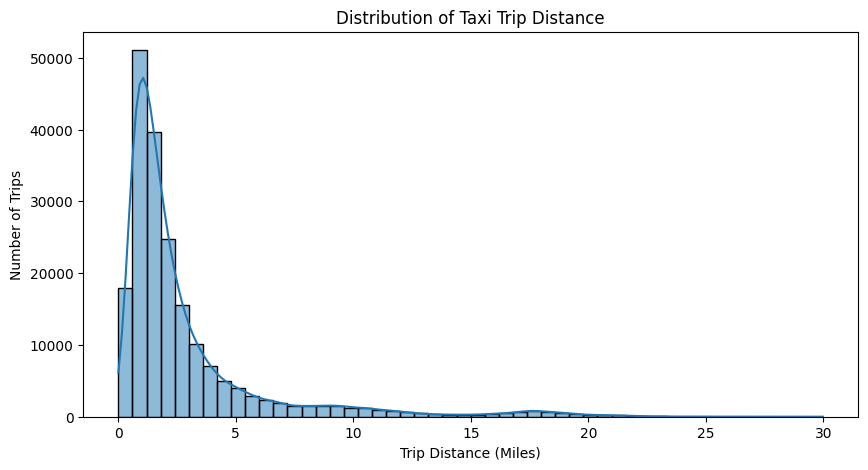

In [25]:
# Analyze trip distance
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda[eda["trip_distance"] <= 30],
    x="trip_distance",
    bins=50,
    kde=True
)

plt.title("Distribution of Taxi Trip Distance")
plt.xlabel("Trip Distance (Miles)")
plt.ylabel("Number of Trips")

plt.show()

# Observation: This graph shows how frequently different trip distances occur. It helps identify common short and long taxi journeys.


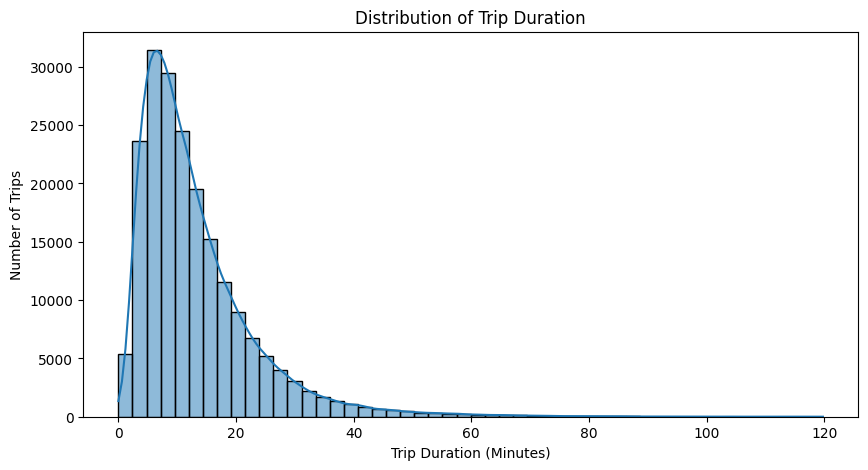

In [26]:
# Analyze trip duration
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda[eda["trip_duration"] <= 120],
    x="trip_duration",
    bins=50,
    kde=True
)

plt.title("Distribution of Trip Duration")
plt.xlabel("Trip Duration (Minutes)")
plt.ylabel("Number of Trips")

plt.show()

# Observation: This graph helps us understand how much time passengers spend travelling in taxis.

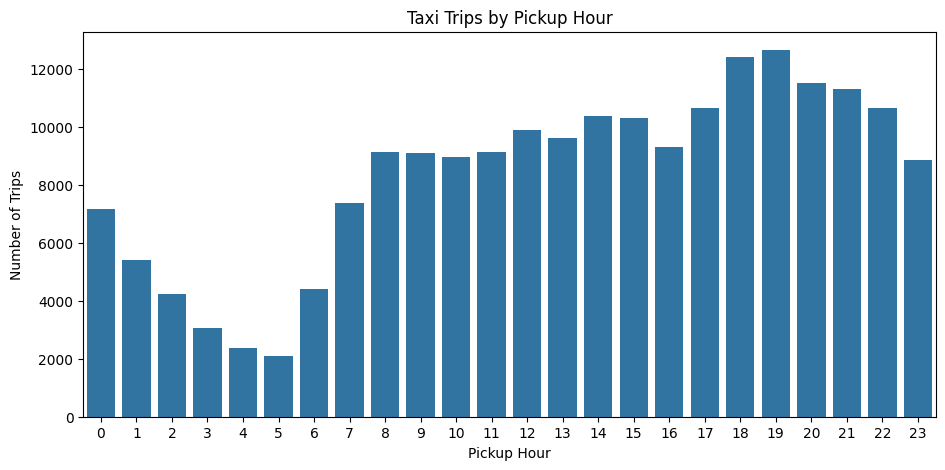

In [27]:
# Analyze trips by pickup hour
eda["pickup_hour"] = (
    eda["tpep_pickup_datetime"].dt.hour
)

hourly_trips = (
    eda["pickup_hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=hourly_trips.index,
    y=hourly_trips.values
)

plt.title("Taxi Trips by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")

plt.xticks(range(24))
plt.show()

# Observation: This graph identifies the hours when taxi demand is higher or lower.

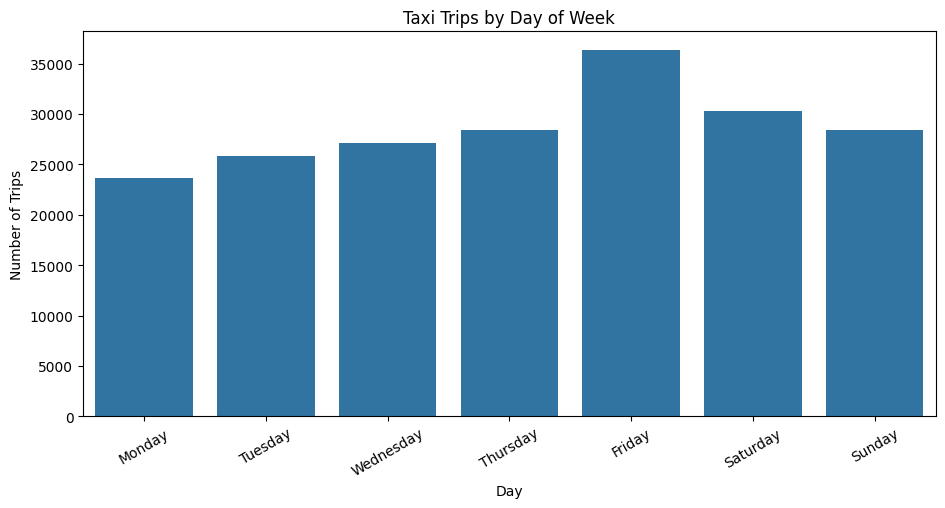

In [28]:
# Analyze trips by day of the week
eda["pickup_day"] = (
    eda["tpep_pickup_datetime"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(11, 5))

sns.countplot(
    data=eda,
    x="pickup_day",
    order=day_order
)

plt.title("Taxi Trips by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Trips")

plt.xticks(rotation=30)
plt.show()

# Observation: This graph compares taxi demand across weekdays and weekends.

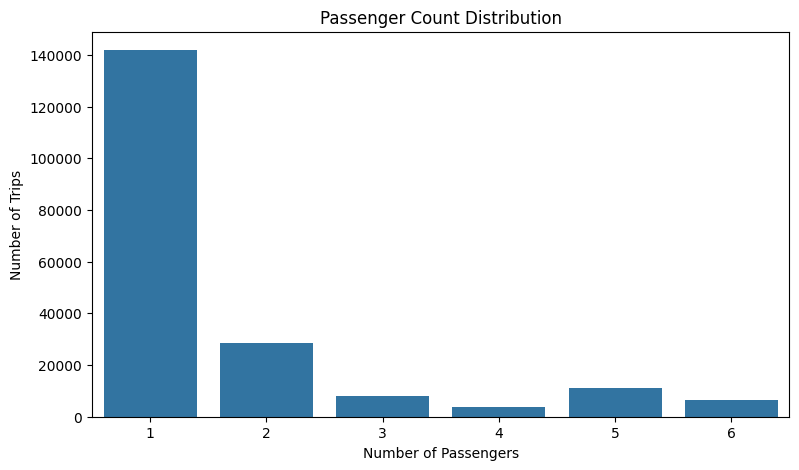

In [29]:
# Analyze passenger count
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda,
    x="passenger_count"
)

plt.title("Passenger Count Distribution")
plt.xlabel("Number of Passengers")
plt.ylabel("Number of Trips")

plt.show()

# Observation: This graph shows the number of taxi trips for different passenger counts.

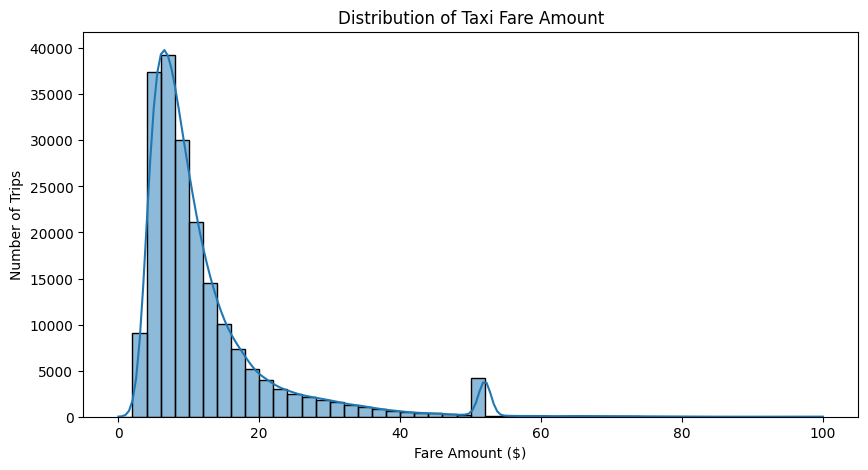

In [30]:
# Analyze fare amount
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda[eda["fare_amount"].between(0, 100)],
    x="fare_amount",
    bins=50,
    kde=True
)

plt.title("Distribution of Taxi Fare Amount")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Number of Trips")

plt.show()

# Observation: This graph shows the distribution of taxi fares and helps identify unusually high fare values.

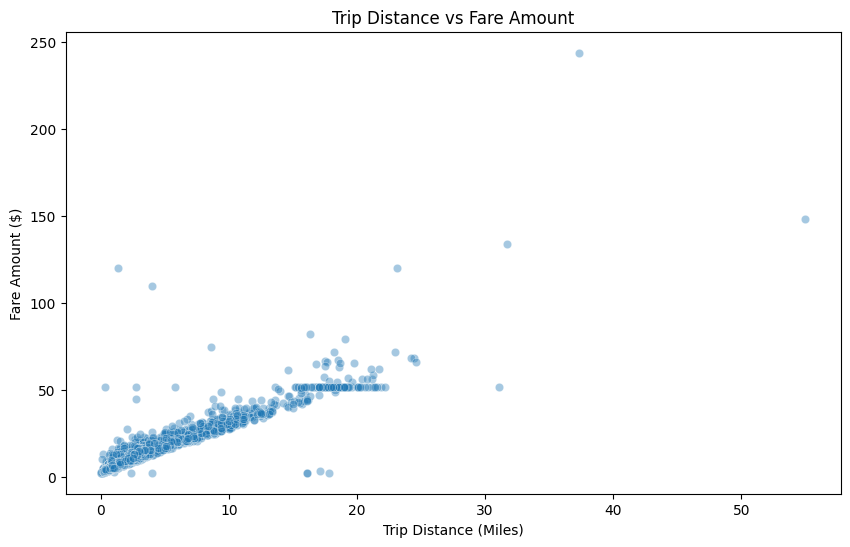

In [31]:
# Analyze fare versus trip distance
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=eda.sample(min(5000, len(eda)), random_state=42),
    x="trip_distance",
    y="fare_amount",
    alpha=0.4
)

plt.title("Trip Distance vs Fare Amount")
plt.xlabel("Trip Distance (Miles)")
plt.ylabel("Fare Amount ($)")

plt.show()

# Observation: This graph helps us understand the relationship between trip distance and fare amount.

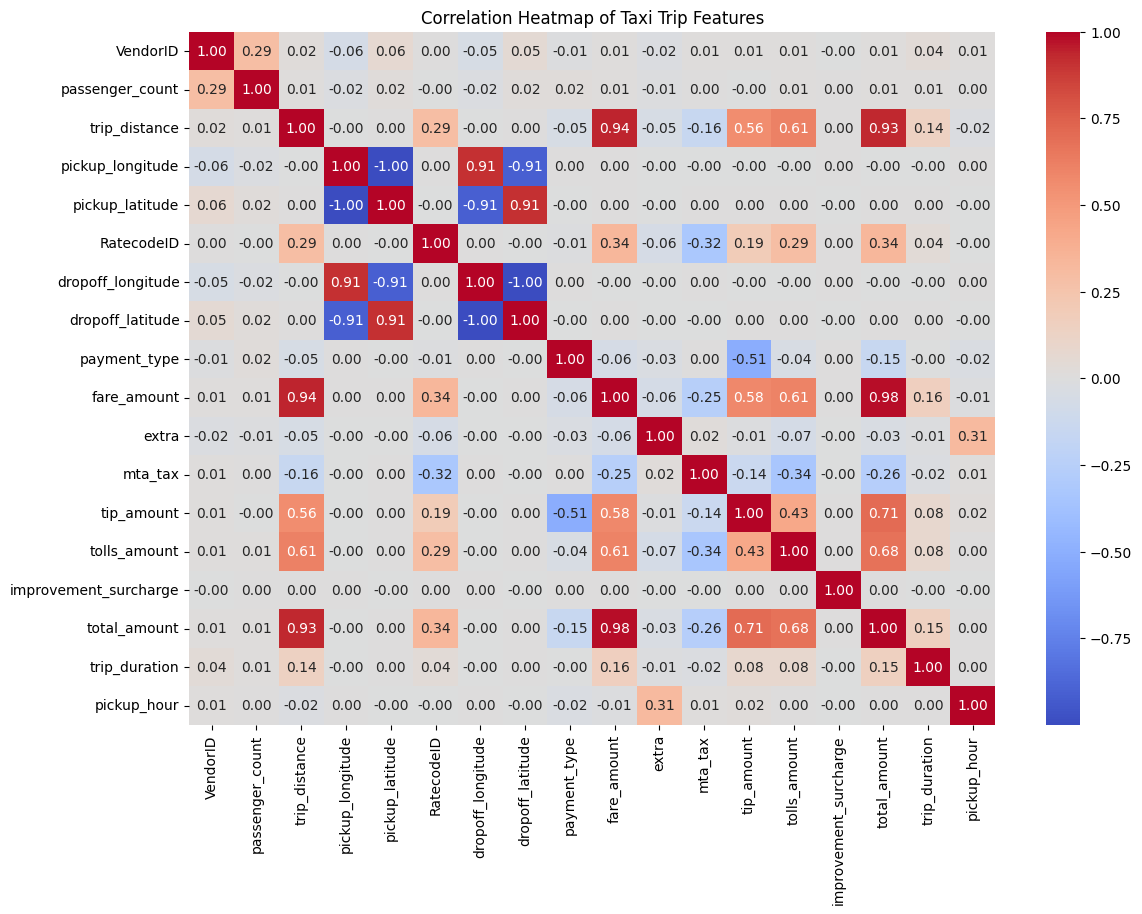

In [32]:
# Analyze correlation between numerical features
numeric_data = eda.select_dtypes(
    include=["number"]
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Taxi Trip Features")
plt.show()

In [33]:
# Final EDA summary
print("       EXPLORATORY DATA ANALYSIS SUMMARY")
print("-" * 50)

print("Total records analyzed:", len(eda))

print("\nAverage trip distance:",
      round(eda["trip_distance"].mean(), 2), "miles")

print("Average trip duration:",
      round(eda["trip_duration"].mean(), 2), "minutes")

print("Average fare amount:",
      round(eda["fare_amount"].mean(), 2))

print("Average passenger count:",
      round(eda["passenger_count"].mean(), 2))

print("\nEDA completed")

       EXPLORATORY DATA ANALYSIS SUMMARY
--------------------------------------------------
Total records analyzed: 200000

Average trip distance: 2.91 miles
Average trip duration: 15.43 minutes
Average fare amount: 12.42
Average passenger count: 1.66

EDA completed


Feature Engineering

In [34]:
# Extract pickup date and time features
df_clean["pickup_hour"] = df_clean["tpep_pickup_datetime"].dt.hour
df_clean["pickup_day"] = df_clean["tpep_pickup_datetime"].dt.day
df_clean["pickup_month"] = df_clean["tpep_pickup_datetime"].dt.month
df_clean["pickup_weekday"] = df_clean["tpep_pickup_datetime"].dt.dayofweek

# Extract dropoff time
df_clean["dropoff_hour"] = df_clean["tpep_dropoff_datetime"].dt.hour

df_clean[[
    "tpep_pickup_datetime",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "pickup_weekday",
    "dropoff_hour"
]].head()

,tpep_pickup_datetime,pickup_hour,pickup_day,pickup_month,pickup_weekday,dropoff_hour
5,2016-01-01 00:00:00,0,1,1,4,0
6,2016-01-01 00:00:00,0,1,1,4,0
7,2016-01-01 00:00:01,0,1,1,4,0
8,2016-01-01 00:00:02,0,1,1,4,0
9,2016-01-01 00:00:02,0,1,1,4,0


In [35]:
# Create trip-related features
# Calculate average speed in miles per hour
df_clean["average_speed"] = (
    df_clean["trip_distance"] / (df_clean["trip_duration"] / 60)
)

# Calculate fare per mile
df_clean["fare_per_mile"] = (
    df_clean["fare_amount"] / df_clean["trip_distance"]
)

# Display new features
df_clean[[
    "trip_distance",
    "trip_duration",
    "average_speed",
    "fare_per_mile"
]].head()

,trip_distance,trip_duration,average_speed,fare_per_mile
5,5.52,18.50,17.902703,3.442029
6,7.45,26.75,16.710280,3.489933
7,1.20,11.90,6.050420,7.500000
8,6.00,11.20,32.142857,3.000000
9,3.21,11.10,17.351351,3.582555


In [36]:
# Check the new features
df_clean[[
    "pickup_hour",
    "pickup_weekday",
    "average_speed",
    "fare_per_mile"
]].describe()

,pickup_hour,pickup_weekday,average_speed,fare_per_mile
count,1.083699e+07,1.083699e+07,1.083699e+07,1.083699e+07
mean,1.355244e+01,3.160260e+00,6.278449e+01,6.541750e+00
std,6.387807e+00,1.938255e+00,1.199686e+05,6.971741e+01
min,0.000000e+00,0.000000e+00,4.171495e-04,1.023995e-06
25%,9.000000e+00,2.000000e+00,7.960396e+00,4.188482e+00
50%,1.400000e+01,3.000000e+00,1.064516e+01,5.312500e+00
75%,1.900000e+01,5.000000e+00,1.444660e+01,6.701031e+00
max,2.300000e+01,6.000000e+00,3.885897e+08,1.236343e+05


In [37]:
# Check invalid values
print("Missing values in new features:")
print(df_clean[[
    "pickup_hour",
    "pickup_weekday",
    "average_speed",
    "fare_per_mile"
]].isnull().sum())

print("\nInfinite values:")
print(
    df_clean[["average_speed", "fare_per_mile"]]
    .isin([float("inf"), -float("inf")])
    .sum()
)

Missing values in new features:
pickup_hour       0
pickup_weekday    0
average_speed     0
fare_per_mile     0
dtype: int64

Infinite values:
average_speed    0
fare_per_mile    0
dtype: int64


In [38]:
import os

INPUT_PATH = "/kaggle/input"

print("Available Kaggle input files:\n")

for root, dirs, files in os.walk(INPUT_PATH):
    for file in files:
        print(os.path.join(root, file))

Available Kaggle input files:

/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-01.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-02.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-03.csv
/kaggle/input/competitions/nyc-transit-optimization-anomaly-challenge-mu-ict-lhc/data


Classification 

In [39]:
import os
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

for file in files:
    path = os.path.join(DATA_PATH, file)

    print("\nFile:", file)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Size (MB):", round(os.path.getsize(path) / (1024**2), 2))


File: yellow_tripdata_2015-01.csv
Exists: True
Size (MB): 1893.96

File: yellow_tripdata_2016-01.csv
Exists: True
Size (MB): 1629.52

File: yellow_tripdata_2016-02.csv
Exists: True
Size (MB): 1700.93

File: yellow_tripdata_2016-03.csv
Exists: True
Size (MB): 1825.97


In [40]:
# Check whether all files have the same columns
column_sets = {}

for file in files:
    path = os.path.join(DATA_PATH, file)
    column_sets[file] = set(pd.read_csv(path, nrows=0).columns)

first_file = files[0]

for file in files[1:]:
    print("\nComparing:", first_file, "with", file)
    print("Same columns:", column_sets[first_file] == column_sets[file])

    print("Missing columns:", column_sets[first_file] - column_sets[file])
    print("Extra columns:", column_sets[file] - column_sets[first_file])


Comparing: yellow_tripdata_2015-01.csv with yellow_tripdata_2016-01.csv
Same columns: False
Missing columns: {'RateCodeID'}
Extra columns: {'RatecodeID'}

Comparing: yellow_tripdata_2015-01.csv with yellow_tripdata_2016-02.csv
Same columns: False
Missing columns: {'RateCodeID'}
Extra columns: {'RatecodeID'}

Comparing: yellow_tripdata_2015-01.csv with yellow_tripdata_2016-03.csv
Same columns: False
Missing columns: {'RateCodeID'}
Extra columns: {'RatecodeID'}


In [41]:
# Standardize column names
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

for file in files:
    path = os.path.join(DATA_PATH, file)

    columns = pd.read_csv(path, nrows=0).columns.tolist()

    if "RateCodeID" in columns:
        columns[columns.index("RateCodeID")] = "RatecodeID"

    print(file, "->", columns)

yellow_tripdata_2015-01.csv -> ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']
yellow_tripdata_2016-01.csv -> ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']
yellow_tripdata_2016-02.csv -> ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare

In [42]:
# Verify the column names
column_sets = {}

for file in files:
    path = os.path.join(DATA_PATH, file)

    columns = pd.read_csv(path, nrows=0).columns.tolist()

    columns = [
        "RatecodeID" if col == "RateCodeID" else col
        for col in columns
    ]

    column_sets[file] = set(columns)

first_file = files[0]

for file in files[1:]:
    print(
        file,
        "Same columns:",
        column_sets[first_file] == column_sets[file]
    )

yellow_tripdata_2016-01.csv Same columns: True
yellow_tripdata_2016-02.csv Same columns: True
yellow_tripdata_2016-03.csv Same columns: True


In [43]:
# Combine all four datasets
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

output_file = "/kaggle/working/combined_taxi_data.csv"

# Remove an earlier output if it exists
if os.path.exists(output_file):
    os.remove(output_file)

first_chunk = True

for file in files:
    path = os.path.join(DATA_PATH, file)

    print("\nProcessing:", file)

    for chunk in pd.read_csv(path, chunksize=200000):

        # Standardize column name
        chunk.rename(
            columns={"RateCodeID": "RatecodeID"},
            inplace=True
        )

        chunk.to_csv(
            output_file,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False

    print("Completed:", file)

print("\nAll four datasets combined successfully!")
print("Output file:", output_file)
print("File size (GB):", round(os.path.getsize(output_file) / (1024**3), 2))


Processing: yellow_tripdata_2015-01.csv
Completed: yellow_tripdata_2015-01.csv

Processing: yellow_tripdata_2016-01.csv
Completed: yellow_tripdata_2016-01.csv

Processing: yellow_tripdata_2016-02.csv
Completed: yellow_tripdata_2016-02.csv

Processing: yellow_tripdata_2016-03.csv
Completed: yellow_tripdata_2016-03.csv

All four datasets combined successfully!
Output file: /kaggle/working/combined_taxi_data.csv
File size (GB): 6.92


In [44]:
# Read only the pickup and drop-off date columns
date_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime"
]

min_date = None
max_date = None

for chunk in pd.read_csv(
    output_file,
    usecols=date_columns,
    chunksize=200000
):
    dates = pd.to_datetime(
        chunk["tpep_pickup_datetime"],
        errors="coerce"
    ).dropna()

    if not dates.empty:
        chunk_min = dates.min()
        chunk_max = dates.max()

        min_date = chunk_min if min_date is None else min(min_date, chunk_min)
        max_date = chunk_max if max_date is None else max(max_date, chunk_max)

print("Earliest pickup:", min_date)
print("Latest pickup:", max_date)

Earliest pickup: 2015-01-01 00:00:00
Latest pickup: 2016-03-31 23:59:59


In [45]:
combined = pd.read_csv(
    "/kaggle/working/combined_taxi_data.csv",
    nrows=5
)

print("Combined dataset columns:")
print(combined.columns.tolist())

print("\nFirst five rows:")
display(combined)

Combined dataset columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']

First five rows:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2015-01-15 19:05:39,2015-01-15 19:23:42,1,1.59,-73.993896,40.750111,1,N,-73.974785,40.750618,1,12.0,1.0,0.5,3.25,0.0,0.3,17.05
1,1,2015-01-10 20:33:38,2015-01-10 20:53:28,1,3.30,-74.001648,40.724243,1,N,-73.994415,40.759109,1,14.5,0.5,0.5,2.00,0.0,0.3,17.80
2,1,2015-01-10 20:33:38,2015-01-10 20:43:41,1,1.80,-73.963341,40.802788,1,N,-73.951820,40.824413,2,9.5,0.5,0.5,0.00,0.0,0.3,10.80
3,1,2015-01-10 20:33:39,2015-01-10 20:35:31,1,0.50,-74.009087,40.713818,1,N,-74.004326,40.719986,2,3.5,0.5,0.5,0.00,0.0,0.3,4.80
4,1,2015-01-10 20:33:39,2015-01-10 20:52:58,1,3.00,-73.971176,40.762428,1,N,-74.004181,40.742653,2,15.0,0.5,0.5,0.00,0.0,0.3,16.30


In [46]:
# Check the date range
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

for file in files:
    path = os.path.join(DATA_PATH, file)

    first = pd.read_csv(path, usecols=["tpep_pickup_datetime"], nrows=1)
    last = pd.read_csv(
        path,
        usecols=["tpep_pickup_datetime"]
    ).tail(1)

    print("\nFile:", file)
    print("First pickup:", first.iloc[0, 0])
    print("Last pickup:", last.iloc[0, 0])


File: yellow_tripdata_2015-01.csv
First pickup: 2015-01-15 19:05:39
Last pickup: 2015-01-10 19:01:45

File: yellow_tripdata_2016-01.csv
First pickup: 2016-01-01 00:00:00
Last pickup: 2016-01-05 06:15:21

File: yellow_tripdata_2016-02.csv
First pickup: 2016-02-25 17:24:20
Last pickup: 2016-02-13 22:48:20

File: yellow_tripdata_2016-03.csv
First pickup: 2016-03-01 00:00:00
Last pickup: 2016-03-20 08:50:24


In [47]:
# Find the actual date range
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

for file in files:
    path = os.path.join(DATA_PATH, file)

    min_date = pd.Timestamp.max
    max_date = pd.Timestamp.min

    for chunk in pd.read_csv(
        path,
        usecols=["tpep_pickup_datetime"],
        chunksize=500000
    ):
        dates = pd.to_datetime(
            chunk["tpep_pickup_datetime"],
            errors="coerce"
        ).dropna()

        if not dates.empty:
            min_date = min(min_date, dates.min())
            max_date = max(max_date, dates.max())

    print("\nFile:", file)
    print("Earliest pickup:", min_date)
    print("Latest pickup:", max_date)

# Observation: We have four months of taxi records across two different years. February 2016 correctly includes 29 days because it was a leap year.


File: yellow_tripdata_2015-01.csv
Earliest pickup: 2015-01-01 00:00:00
Latest pickup: 2015-01-31 23:59:59

File: yellow_tripdata_2016-01.csv
Earliest pickup: 2016-01-01 00:00:00
Latest pickup: 2016-01-31 23:59:59

File: yellow_tripdata_2016-02.csv
Earliest pickup: 2016-02-01 00:00:00
Latest pickup: 2016-02-29 23:59:58

File: yellow_tripdata_2016-03.csv
Earliest pickup: 2016-03-01 00:00:00
Latest pickup: 2016-03-31 23:59:59


In [48]:
# Check records by month
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

for file in files:
    path = os.path.join(DATA_PATH, file)

    total_rows = 0

    for chunk in pd.read_csv(
        path,
        usecols=["VendorID"],
        chunksize=500000
    ):
        total_rows += len(chunk)

    print(file, ":", f"{total_rows:,}", "records")

yellow_tripdata_2015-01.csv : 12,748,986 records
yellow_tripdata_2016-01.csv : 10,906,858 records
yellow_tripdata_2016-02.csv : 11,382,049 records
yellow_tripdata_2016-03.csv : 12,210,952 records


In [49]:
# Create a dataset summary
import pandas as pd

summary = pd.DataFrame({
    "Month": [
        "January 2015",
        "January 2016",
        "February 2016",
        "March 2016"
    ],
    "Total Records": [
        12748986,
        10906858,
        11382049,
        12210952
    ]
})

summary["Total Records"] = summary["Total Records"].map(
    lambda x: f"{x:,}"
)

display(summary)

,Month,Total Records
0,January 2015,"12,748,986"
1,January 2016,"10,906,858"
2,February 2016,"11,382,049"
3,March 2016,"12,210,952"


In [50]:
# Create the modelling dataset
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data"

files = [
    "yellow_tripdata_2015-01.csv",
    "yellow_tripdata_2016-01.csv",
    "yellow_tripdata_2016-02.csv",
    "yellow_tripdata_2016-03.csv"
]

sampled_data = []

for file in files:

    path = os.path.join(DATA_PATH, file)

    print("\nProcessing:", file)

    chunk_samples = []

    for chunk in pd.read_csv(path, chunksize=500000):

        # Standardize column name
        chunk.rename(
            columns={"RateCodeID": "RatecodeID"},
            inplace=True
        )

        # Take a small random sample from each chunk
        small_sample = chunk.sample(
            n=min(2500, len(chunk)),
            random_state=42
        )

        chunk_samples.append(small_sample)

    # Combine samples from the current file
    file_sample = pd.concat(
        chunk_samples,
        ignore_index=True
    )

    # Select 50,000 records from each file
    file_sample = file_sample.sample(
        n=min(50000, len(file_sample)),
        random_state=42
    )

    file_sample["source_file"] = file

    sampled_data.append(file_sample)

    print("Sample records:", len(file_sample))

# Combine samples from all four files
model_df = pd.concat(
    sampled_data,
    ignore_index=True
)

# Shuffle the combined sample
model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\nModelling dataset created!")
print("Shape:", model_df.shape)

# Save the modelling dataset
output_path = "/kaggle/working/modelling_dataset.csv"

model_df.to_csv(output_path, index=False)

print("Saved at:", output_path)


Processing: yellow_tripdata_2015-01.csv
Sample records: 50000

Processing: yellow_tripdata_2016-01.csv
Sample records: 50000

Processing: yellow_tripdata_2016-02.csv
Sample records: 50000

Processing: yellow_tripdata_2016-03.csv
Sample records: 50000

Modelling dataset created!
Shape: (200000, 20)
Saved at: /kaggle/working/modelling_dataset.csv


In [51]:
print("Dataset shape:", model_df.shape)

print("\nRecords from each file:")
print(model_df["source_file"].value_counts())

print("\nDataset columns:")
print(model_df.columns.tolist())

print("\nFirst five records:")
display(model_df.head())

Dataset shape: (200000, 20)

Records from each file:
source_file
yellow_tripdata_2016-02.csv    50000
yellow_tripdata_2016-01.csv    50000
yellow_tripdata_2016-03.csv    50000
yellow_tripdata_2015-01.csv    50000
Name: count, dtype: int64

Dataset columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'source_file']

First five records:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,source_file
0,1,2016-02-14 21:44:30,2016-02-14 21:52:28,1,2.6,-73.992729,40.733768,1,N,-74.016045,40.715008,2,9.5,0.5,0.5,0.00,0.0,0.3,10.80,yellow_tripdata_2016-02.csv
1,1,2016-01-16 10:27:23,2016-01-16 10:37:43,2,3.1,-73.984131,40.720978,1,N,-74.006371,40.714069,1,11.5,0.0,0.5,2.00,0.0,0.3,14.30,yellow_tripdata_2016-01.csv
2,1,2016-03-04 18:22:38,2016-03-04 18:24:38,1,0.5,-73.984879,40.732185,1,N,-73.986382,40.726536,1,3.5,1.0,0.5,1.32,0.0,0.3,6.62,yellow_tripdata_2016-03.csv
3,1,2016-01-25 23:08:00,2016-01-25 23:23:17,1,3.4,-73.958923,40.775105,1,N,-73.997482,40.756313,1,13.5,0.5,0.5,2.00,0.0,0.3,16.80,yellow_tripdata_2016-01.csv
4,1,2015-01-07 08:51:46,2015-01-07 09:06:48,1,2.1,-73.974281,40.752731,1,N,-73.954140,40.764023,1,11.0,0.0,0.5,3.54,0.0,0.3,15.34,yellow_tripdata_2015-01.csv


In [52]:
# Prepare the date column
import pandas as pd

# Convert pickup time into datetime format
model_df["tpep_pickup_datetime"] = pd.to_datetime(
    model_df["tpep_pickup_datetime"],
    errors="coerce"
)

# Remove rows with invalid pickup dates
model_df = model_df.dropna(
    subset=["tpep_pickup_datetime"]
)

# Sort records by pickup time
model_df = model_df.sort_values(
    by="tpep_pickup_datetime"
).reset_index(drop=True)

print("Dataset shape:", model_df.shape)
print("Earliest date:", model_df["tpep_pickup_datetime"].min())
print("Latest date:", model_df["tpep_pickup_datetime"].max())

Dataset shape: (200000, 20)
Earliest date: 2015-01-01 00:01:50
Latest date: 2016-03-31 23:59:48


In [53]:
# Split into training and testing data
# Calculate 80% training size
split_index = int(len(model_df) * 0.80)

# Create chronological split
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nTraining date range:")
print(train_df["tpep_pickup_datetime"].min())
print(train_df["tpep_pickup_datetime"].max())

print("\nTesting date range:")
print(test_df["tpep_pickup_datetime"].min())
print(test_df["tpep_pickup_datetime"].max())

Training dataset: (160000, 20)
Testing dataset: (40000, 20)

Training date range:
2015-01-01 00:01:50
2016-03-07 07:18:39

Testing date range:
2016-03-07 07:18:52
2016-03-31 23:59:48


In [54]:
# Save both datasets
train_df.to_csv(
    "/kaggle/working/train_dataset.csv",
    index=False
)

test_df.to_csv(
    "/kaggle/working/test_dataset.csv",
    index=False
)

print("Training and testing datasets saved")

Training and testing datasets saved


Pillar A — Classification (Surge Tier Prediction)

In [55]:
# Create surge-related features
import numpy as np
import pandas as pd

# Work with copies of the existing datasets
train_df = train_df.copy()
test_df = test_df.copy()

for data in [train_df, test_df]:

    # Extract time features
    data["pickup_hour"] = data["tpep_pickup_datetime"].dt.hour
    data["pickup_weekday"] = data["tpep_pickup_datetime"].dt.dayofweek

    # Identify peak hours
    data["is_peak_hour"] = data["pickup_hour"].isin(
        [7, 8, 9, 16, 17, 18, 19]
    ).astype(int)

    # Identify weekends
    data["is_weekend"] = (
        data["pickup_weekday"] >= 5
    ).astype(int)

    # Calculate fare per mile
    data["fare_per_mile"] = (
        data["fare_amount"] /
        data["trip_distance"].replace(0, np.nan)
    )

    data["fare_per_mile"] = data["fare_per_mile"].replace(
        [np.inf, -np.inf], np.nan
    )

In [56]:
# Define experimental thresholds
distance_threshold = train_df["trip_distance"].quantile(0.75)

fare_threshold = train_df["fare_per_mile"].quantile(0.75)

print("High distance threshold:", distance_threshold)
print("High fare per mile threshold:", fare_threshold)

High distance threshold: 3.05
High fare per mile threshold: 6.666666666666667


In [57]:
# Construct the surge target
def create_surge_target(data):

    score = (
        data["is_peak_hour"]
        + data["is_weekend"]
        + (data["trip_distance"] >= distance_threshold).astype(int)
        + (data["fare_per_mile"] >= fare_threshold).astype(int)
    )

    data["surge_score"] = score

    data["surge_tier"] = np.select(
        [
            score <= 1,
            score == 2
        ],
        [
            0,
            1
        ],
        default=2
    )

    return data


train_df = create_surge_target(train_df)
test_df = create_surge_target(test_df)

print("Surge target created")

Surge target created


In [58]:
# Check class distribution
print("Training target distribution:")
print(train_df["surge_tier"].value_counts().sort_index())

print("\nTesting target distribution:")
print(test_df["surge_tier"].value_counts().sort_index())

Training target distribution:
surge_tier
0    108260
1     45308
2      6432
Name: count, dtype: int64

Testing target distribution:
surge_tier
0    27878
1    10795
2     1327
Name: count, dtype: int64


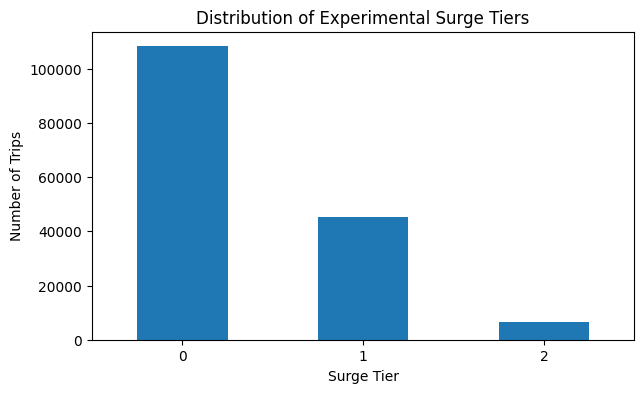

In [59]:
import matplotlib.pyplot as plt

train_df["surge_tier"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution of Experimental Surge Tiers")
plt.xlabel("Surge Tier")
plt.ylabel("Number of Trips")
plt.xticks(rotation=0)
plt.show()

# Most trips belong to Surge Tier 0 (Low), while very few trips belong to Surge Tier 2 (High). This shows that the target classes are imbalanced. We should consider this during model evaluation.

In [60]:
# Feature Preparation
# Select input features for Surge Tier Prediction

features = [
    "pickup_hour",
    "pickup_weekday",
    "is_peak_hour",
    "is_weekend",
    "trip_distance",
    "fare_amount",
    "fare_per_mile",
    "passenger_count",
    "payment_type",
    "RatecodeID"
]

target = "surge_tier"

# Create feature and target datasets
X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

# Convert categorical columns into numeric values
X_train = pd.get_dummies(X_train, columns=["payment_type", "RatecodeID"])
X_test = pd.get_dummies(X_test, columns=["payment_type", "RatecodeID"])

# Make sure training and testing have the same columns
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

# Replace missing and infinite values
X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0)
X_test = X_test.replace([np.inf, -np.inf], np.nan).fillna(0)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (160000, 19)
Testing feature shape: (40000, 19)
Training target shape: (160000,)
Testing target shape: (40000,)


Model Development

In [61]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained")

Random Forest model trained


Model Evaluation

Model Accuracy: 99.98 %

Classification Report:
              precision    recall  f1-score   support

   Low Surge       1.00      1.00      1.00     27878
Medium Surge       1.00      1.00      1.00     10795
  High Surge       1.00      1.00      1.00      1327

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



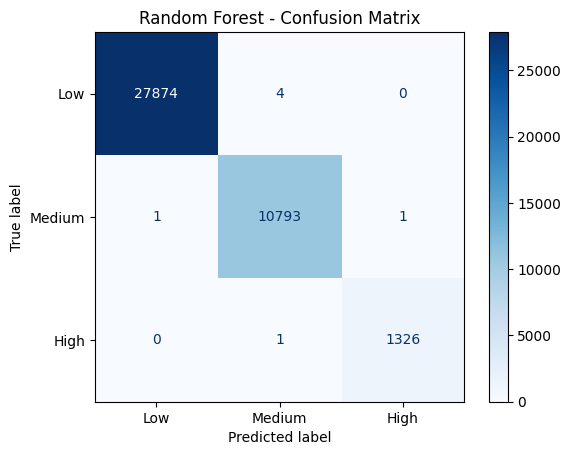

In [62]:
# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict surge tiers for testing data
y_pred = rf_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low Surge", "Medium Surge", "High Surge"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [63]:
# Prediction Generation
# Generate predictions
final_predictions = rf_model.predict(X_test)

# Create prediction DataFrame
prediction_df = pd.DataFrame({
    "Actual_Surge_Tier": y_test.values,
    "Predicted_Surge_Tier": final_predictions
})

# Add predicted probabilities
probabilities = rf_model.predict_proba(X_test)

prediction_df["Low_Probability"] = probabilities[:, 0]
prediction_df["Medium_Probability"] = probabilities[:, 1]
prediction_df["High_Probability"] = probabilities[:, 2]

# Save predictions
prediction_df.to_csv(
    "/kaggle/working/surge_tier_predictions.csv",
    index=False
)

print("Predictions generated successfully")
print("Prediction shape:", prediction_df.shape)


print("\nPredicted class distribution:")
print(prediction_df["Predicted_Surge_Tier"].value_counts().sort_index())

Predictions generated successfully
Prediction shape: (40000, 5)

Predicted class distribution:
Predicted_Surge_Tier
0    27875
1    10798
2     1327
Name: count, dtype: int64


In [64]:
from IPython.display import display as show_table

print("Predictions generated successfully")
print("Prediction shape:", prediction_df.shape)

print("\nFirst 10 predictions:")
show_table(prediction_df.head(10))

print("\nPredicted class distribution:")
print(
    prediction_df["Predicted_Surge_Tier"]
    .value_counts()
    .sort_index()
)

Predictions generated successfully
Prediction shape: (40000, 5)

First 10 predictions:


,Actual_Surge_Tier,Predicted_Surge_Tier,Low_Probability,Medium_Probability,High_Probability
0,0,0,0.996191,0.003809,0.0
1,0,0,0.994318,0.005682,0.0
2,1,1,0.000158,0.999842,0.0
3,0,0,0.999737,0.000263,0.0
4,0,0,0.997096,0.002904,0.0
5,0,0,0.999583,0.000417,0.0
6,0,0,0.993108,0.006892,0.0
7,0,0,0.991971,0.008029,0.0
8,0,0,0.995664,0.004336,0.0
9,1,1,0.007359,0.992641,0.0



Predicted class distribution:
Predicted_Surge_Tier
0    27875
1    10798
2     1327
Name: count, dtype: int64


In [65]:
import os

file_path = "/kaggle/working/surge_tier_predictions.csv"

if os.path.exists(file_path):
    print("File saved successfully")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File saved successfully
File size: 1407.52 KB
